In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib.patches import RegularPolygon

LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"

In [2]:
def axial_to_pixel(q, r, R):
    """Flat-top hexagon axial coordinates -> Cartesian pixel coordinates."""
    x = 1.5 * R * q
    y = np.sqrt(3) * R * (r + q / 2.0)
    return x, y

In [3]:
def build_cluster(i, j):
    """Cluster size N and the two lattice vectors that generate it."""
    N = i**2 + i * j + j**2
    A = (i, j)
    B = (-j, i + j)
    return N, A, B

In [4]:
def make_labeller(i, j, N):

    pair_to_id = {}

    def label(q, r):
        u = ((i + j) * q + j * r) % N
        v = (-j * q + i * r) % N
        key = (u, v)
        if key not in pair_to_id:
            pair_to_id[key] = len(pair_to_id)
        return pair_to_id[key]

    return label


In [5]:
def generate_reuse_pattern(i, j, R=1.0, grid_span=7, save=True):
    """Build one complete reuse pattern and return (figure, results dict)."""
    N, A, B = build_cluster(i, j)
    label = make_labeller(i, j, N)
    centers = []
    window = grid_span * 1.55 * R
    for q in range(-grid_span - 2, grid_span + 3):
        for r in range(-grid_span - 2, grid_span + 3):
            x, y = axial_to_pixel(q, r, R)
            if abs(x) > window or abs(y) > window:
                continue
            centers.append((x, y, label(q, r)))
    n_labels = len({lab for _, _, lab in centers})
    assert n_labels == N, f"labelling produced {n_labels} labels, expected {N}"
    fig, ax = plt.subplots(figsize=(7.2, 7.2))
    for x, y, lab in centers:
        color = "#e74c3c" if lab == 0 else "#dfe6e9"
        ax.add_patch(RegularPolygon(
            (x, y), numVertices=6, radius=R * 0.985, orientation=0,
            edgecolor="black", facecolor=color, linewidth=0.8))
        letter = LETTERS[lab] if lab < 26 else str(lab)
        ax.text(x, y, letter, ha="center", va="center", fontsize=9,
                fontweight="bold" if lab == 0 else "normal",
                color="white" if lab == 0 else "black")


    co = np.array([(x, y) for x, y, lab in centers if lab == 0])
    nearest = []
    for x0, y0 in co:
        d = np.hypot(co[:, 0] - x0, co[:, 1] - y0)
        d = d[d > 1e-9]
        if len(d):
            nearest.append(d.min())
    D_measured = float(np.median(nearest))
    D_theory = R * np.sqrt(3 * N)
    assert abs(D_measured - D_theory) < 1e-6 * R, "geometry check failed!"


    p0 = co[np.argmin(np.hypot(co[:, 0], co[:, 1]))]
    d0 = np.hypot(co[:, 0] - p0[0], co[:, 1] - p0[1])
    d0[d0 < 1e-9] = np.inf
    p1 = co[np.argmin(d0)]
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], "b--", lw=2)
    ax.annotate(f"D = {D_measured:.3f}", ((p0[0]+p1[0])/2, (p0[1]+p1[1])/2),
                textcoords="offset points", xytext=(0, 10),
                color="blue", fontsize=11, fontweight="bold", ha="center")

    ax.set_xlim(-window - R, window + R)
    ax.set_ylim(-window - R, window + R)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"Frequency Reuse Pattern, N = {N}  (i = {i}, j = {j})   "
                 f"D/R = {D_measured/R:.3f}", fontsize=12)
    fname = f"reuse_N{N}.png"
    if save:
        fig.savefig(fname, dpi=200, bbox_inches="tight")


    n_path = 4.0 
    Q = D_theory / R    
    sir_db = 10 * np.log10((Q ** n_path) / 6.0) 
    total_channels = 420   
    per_cell = total_channels // N

    return fig, dict(N=N, i=i, j=j, ratio_theory=D_theory / R,
                     ratio_measured=D_measured / R, sir_db=sir_db,
                     channels_per_cell=per_cell, file=fname)

In [6]:
def generate_patterns_overview(results, fname="reuse_patterns_overview.png"):
    fig, axes = plt.subplots(2, 3, figsize=(15, 10.5))
    for ax, res in zip(axes.flat, results):
        ax.imshow(mpimg.imread(res["file"]))
        ax.axis("off")
        ax.set_title(f"N = {res['N']}   D/R = {res['ratio_measured']:.3f}   "
                     f"SIR = {res['sir_db']:.1f} dB", fontsize=11)
    fig.suptitle("Frequency reuse patterns for all valid cluster sizes "
                 "N = 3, 4, 7, 9, 12, 13", fontsize=14)
    fig.tight_layout()
    fig.savefig(fname, dpi=150, bbox_inches="tight")
    return fig


In [7]:
def generate_tradeoff_curve(results, fname="tradeoff_curve.png"):
    Ns = np.array([r["N"] for r in results])
    sir = np.array([r["sir_db"] for r in results])
    ch = np.array([r["channels_per_cell"] for r in results])

    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(Ns, sir, "o-", color="tab:green", lw=2)
    ax1.set_xlabel("Cluster size N")
    ax1.set_ylabel("First-tier SIR (dB)", color="tab:green")
    ax1.tick_params(axis="y", labelcolor="tab:green")
    ax1.axhline(18, color="gray", ls=":", lw=1)
    ax1.text(Ns[0] + 0.1, 18.3, "typical 18 dB requirement",
             fontsize=9, color="gray")
    ax2 = ax1.twinx()
    ax2.plot(Ns, ch, "s--", color="tab:purple", lw=2)
    ax2.set_ylabel("Channels per cell (420 total)", color="tab:purple")
    ax2.tick_params(axis="y", labelcolor="tab:purple")
    plt.title("Capacity vs Interference tradeoff across cluster sizes")
    fig.tight_layout()
    fig.savefig(fname, dpi=150)
    return fig

  N   (i,j)  D/R theory  D/R measured  SIR (dB)  ch/cell
--------------------------------------------------------
  3 (1,1)       3.000         3.000     11.30      140
  4 (2,0)       3.464         3.464     13.80      105
  7 (1,2)       4.583         4.583     18.66       60
  9 (3,0)       5.196         5.196     20.85       46
 12 (2,2)       6.000         6.000     23.34       35
 13 (1,3)       6.245         6.245     24.04       32

All geometry checks passed: measured D/R = sqrt(3N) exactly.
Saved: reuse_N3.png, reuse_N4.png, reuse_N7.png, reuse_N9.png, reuse_N12.png, reuse_N13.png, reuse_patterns_overview.png, tradeoff_curve.png


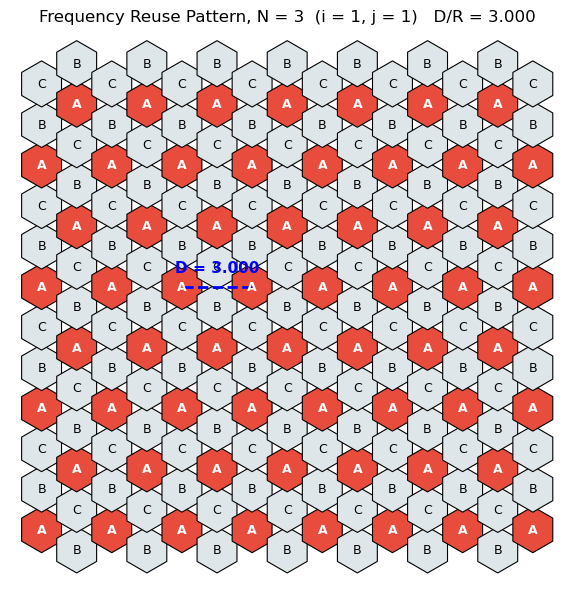

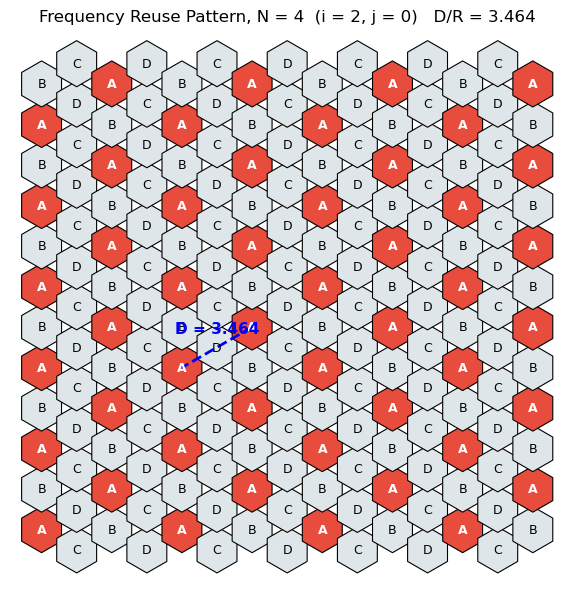

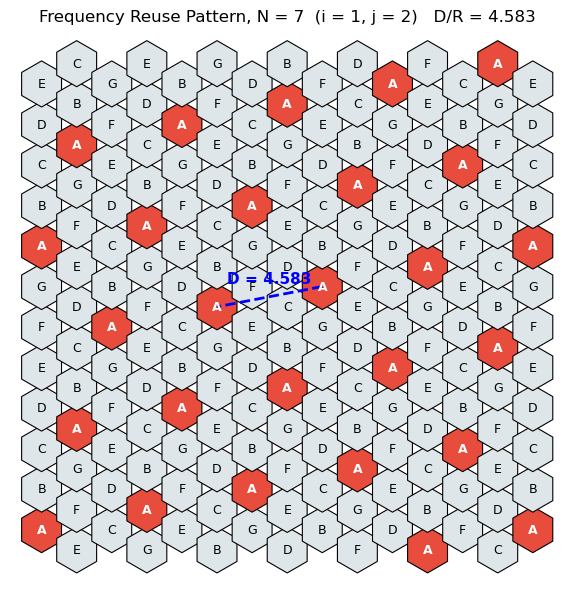

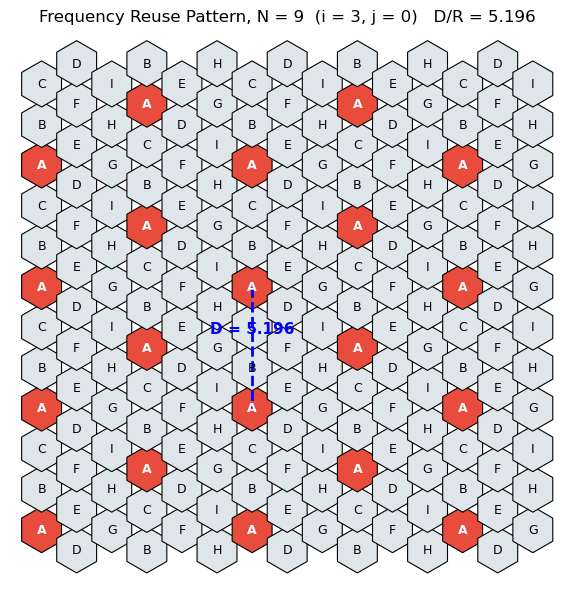

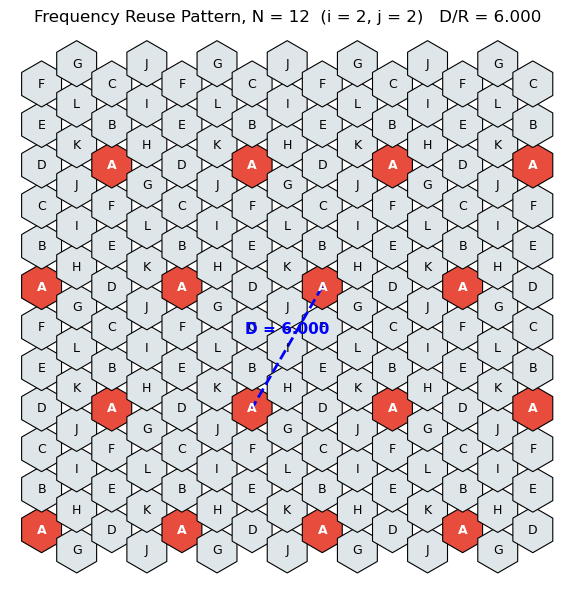

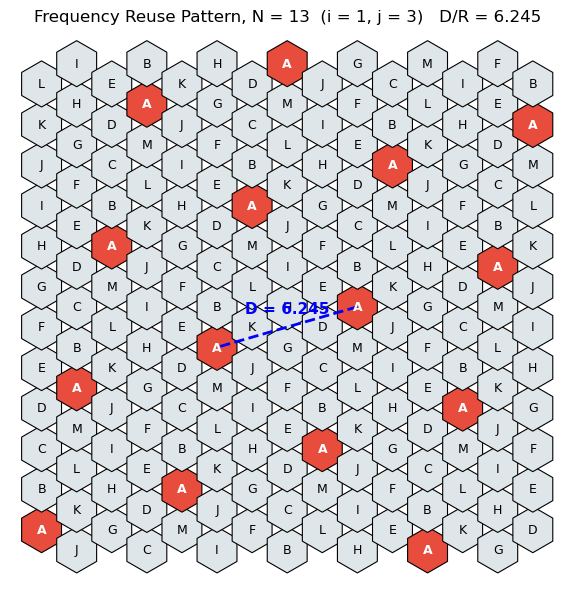

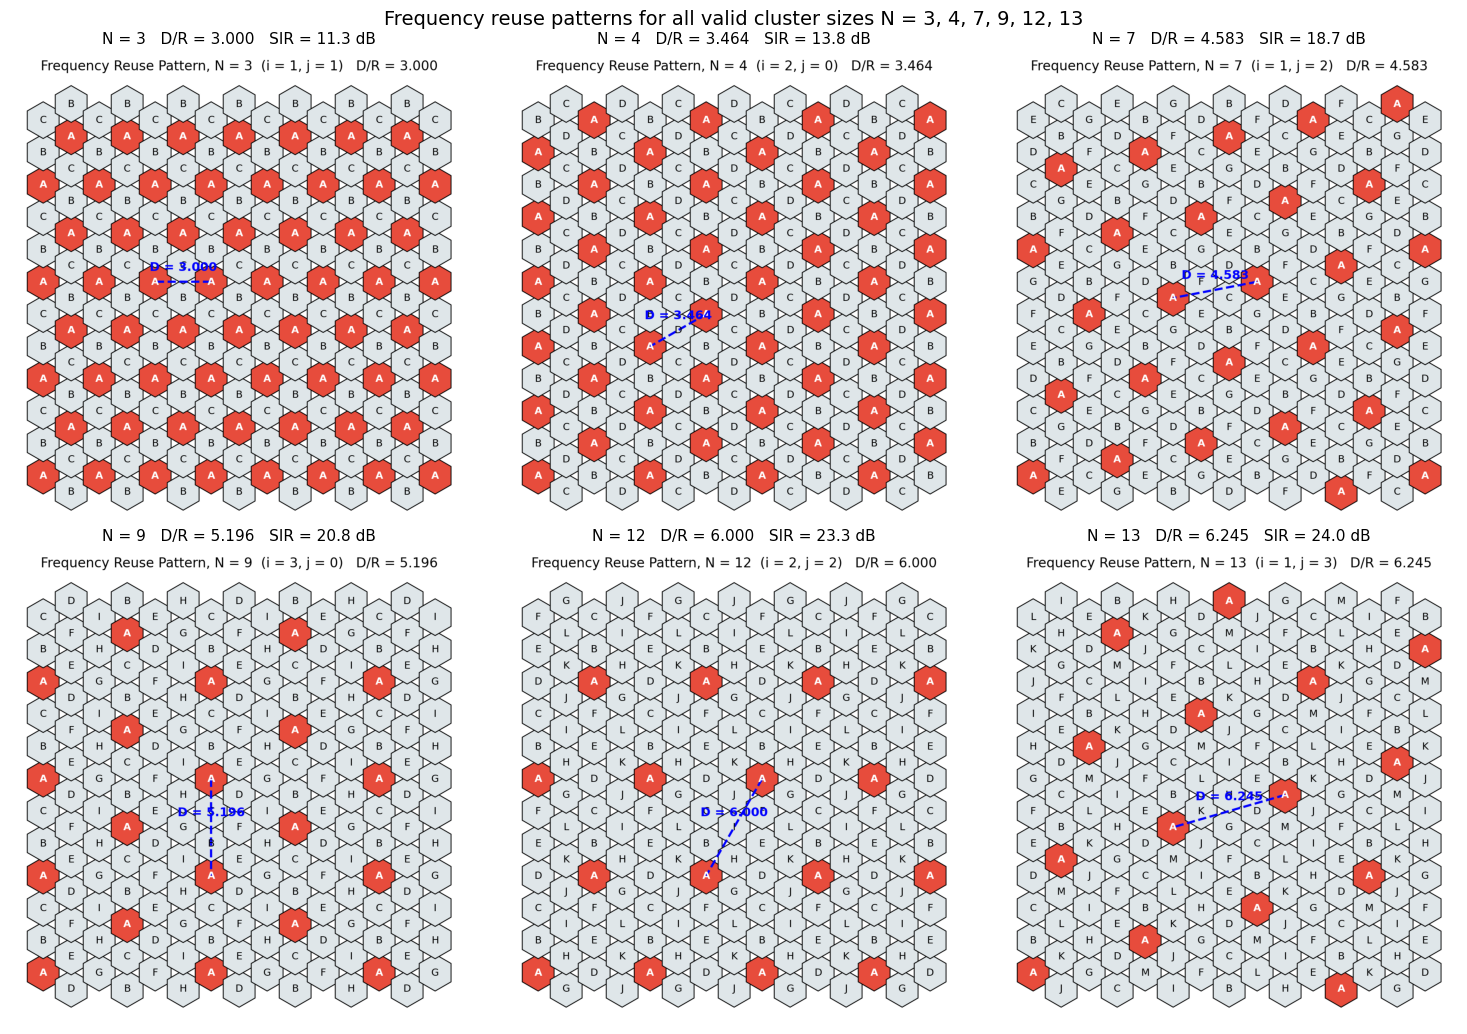

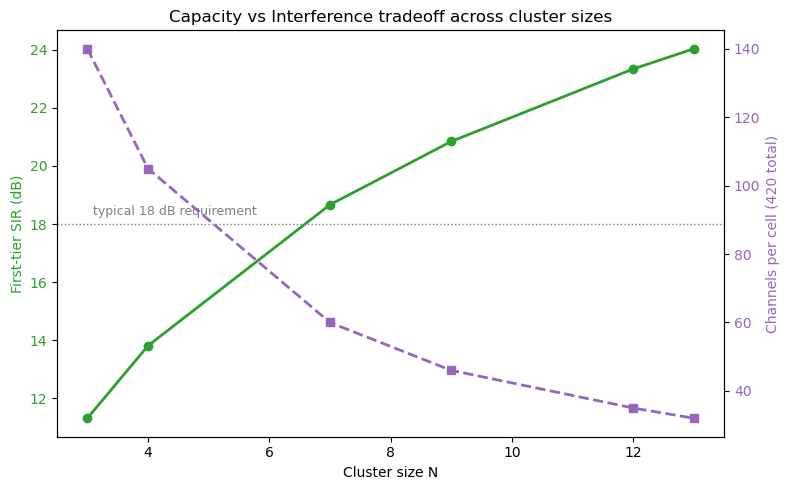

In [8]:
if __name__ == "__main__":
    configs = [(1, 1), (2, 0), (1, 2), (3, 0), (2, 2), (1, 3)]
    # N =        3       4       7       9       12      13
    hdr = (f"{'N':>3} {'(i,j)':>7} {'D/R theory':>11} {'D/R measured':>13} "
           f"{'SIR (dB)':>9} {'ch/cell':>8}")
    print(hdr); print("-" * len(hdr))
    results = []
    for i, j in configs:
        fig, res = generate_reuse_pattern(i, j)
        results.append(res)
        print(f"{res['N']:>3} ({res['i']},{res['j']})"
              f"{res['ratio_theory']:>12.3f}{res['ratio_measured']:>14.3f}"
              f"{res['sir_db']:>10.2f}{res['channels_per_cell']:>9}")
    generate_patterns_overview(results)
    generate_tradeoff_curve(results)
    print("\nAll geometry checks passed: measured D/R = sqrt(3N) exactly.")
    print("Saved: " + ", ".join(r["file"] for r in results)
          + ", reuse_patterns_overview.png, tradeoff_curve.png")
    plt.show()   # display every reuse pattern + overview + tradeoff curve